In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Load data
df = pd.read_csv('data_v2.csv')

# Drop Time and Amount (or scale them) - V1-V28 are already PCA-transformed
data = df.drop(['Time'], axis=1)
data['Amount'] = StandardScaler().fit_transform(data['Amount'].values.reshape(-1, 1))

# Split into Normal and Fraud
X_normal = data[data['Class'] == 0].drop('Class', axis=1)
X_fraud = data[data['Class'] == 1].drop('Class', axis=1)

# Train the Autoencoder ONLY on Normal data
X_train, X_test = train_test_split(X_normal, test_size=0.2, random_state=42)

print(f"Training on {X_train.shape} normal transactions.")

Training on (227452, 29) normal transactions.


In [9]:
import tensorflow as tf
from tensorflow.keras import layers, models, Input

# 1. Define the Input Shape explicitly using the number of features
# Your data has 29 features (V1-V28 + Amount)
input_dim = 29 
input_layer = Input(shape=(input_dim,))

# 2. Define Encoder
encoder_out = layers.Dense(16, activation="relu")(input_layer)
encoder_out = layers.Dense(8, activation="relu")(encoder_out)
bottleneck = layers.Dense(4, activation="relu")(encoder_out)

# 3. Define Decoder
decoder_out = layers.Dense(8, activation="relu")(bottleneck)
decoder_out = layers.Dense(16, activation="relu")(decoder_out)
# Output must match the input dimension (29)
output_layer = layers.Dense(input_dim, activation="sigmoid")(decoder_out)

# 4. Construct the Autoencoder Model
autoencoder = models.Model(inputs=input_layer, outputs=output_layer)

# 5. Compile
autoencoder.compile(optimizer='adam', loss='mse')

print(f"Model built successfully for {input_dim} features!")
autoencoder.summary()

Model built successfully for 29 features!


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 29)             │           493 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,329 (5.19 KB)

 Trainable params: 1,329 (5.19 KB)

 Non-trainable params: 0 (0.00 B)

1777/1777 ━━━━━━━━━━━━━━━━━━━━ 1s 606us/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


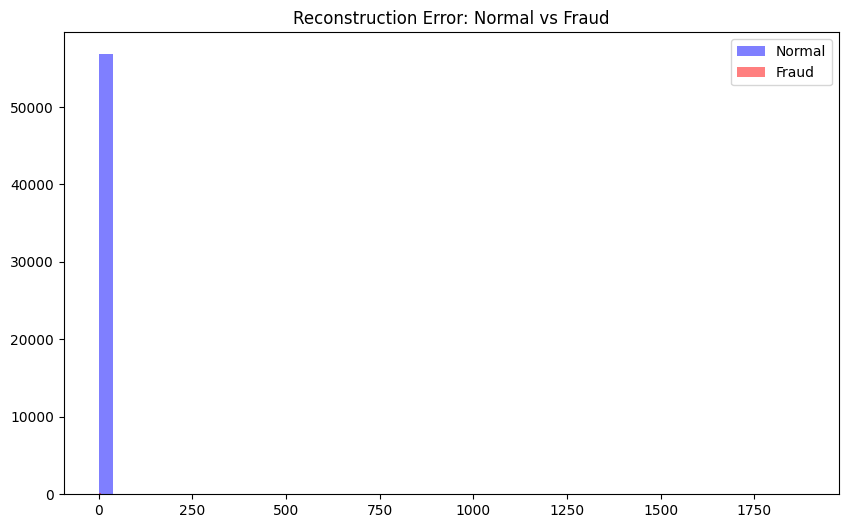

In [13]:
# Predict on the test set (Normal data) and the Fraud data
predictions_normal = autoencoder.predict(X_test)
predictions_fraud = autoencoder.predict(X_fraud)

# Calculate Mean Squared Error (Reconstruction Error)
mse_normal = np.mean(np.power(X_test - predictions_normal, 2), axis=1)
mse_fraud = np.mean(np.power(X_fraud - predictions_fraud, 2), axis=1)

# Plotting the difference
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.hist(mse_normal, bins=50, alpha=0.5, label='Normal', color='blue')
plt.hist(mse_fraud, bins=50, alpha=0.5, label='Fraud', color='red')
plt.title('Reconstruction Error: Normal vs Fraud')
plt.legend()
plt.show()



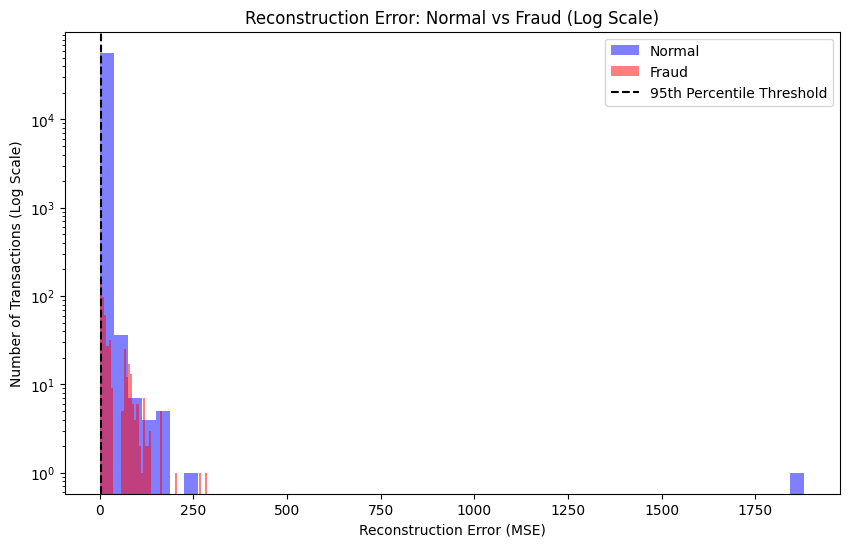

Recommended Threshold for Anomaly Detection: 2.4612


In [14]:
plt.figure(figsize=(10,6))

# Use log=True to make the tiny fraud bars visible
plt.hist(mse_normal, bins=50, alpha=0.5, label='Normal', color='blue', log=True)
plt.hist(mse_fraud, bins=50, alpha=0.5, label='Fraud', color='red', log=True)

# Add a threshold line (this is where you'd flag fraud)
threshold = np.percentile(mse_normal, 95)
plt.axvline(threshold, color='black', linestyle='--', label='95th Percentile Threshold')

plt.title('Reconstruction Error: Normal vs Fraud (Log Scale)')
plt.xlabel('Reconstruction Error (MSE)')
plt.ylabel('Number of Transactions (Log Scale)')
plt.legend()
plt.show()

print(f"Recommended Threshold for Anomaly Detection: {threshold:.4f}")

In [15]:
# Save the model to the models folder
autoencoder.save('../../models/autoencoder_fraud_model.h5')
print("Deep Learning Model Saved Successfully!")

Deep Learning Model Saved Successfully!
